# Latent Diffusion Model on FashionMNIST
VAE-compressed latent space (`stabilityai/sd-vae-ft-mse`) + class-conditional U-Net denoiser with classifier-free guidance.

**Pipeline:** (0) setup -> (1) VAE compression -> (2) latent forward diffusion -> (3) U-Net -> (4) training -> (5) CFG sampling

## Step 0 - Setup, seeding, run log

In [1]:
!pip -q install diffusers accelerate transformers
import os, time, math, json, random
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import torchvision, torchvision.transforms as T
from torchvision.utils import make_grid
from diffusers import AutoencoderKL

# ---- Step 0 (same convention as Assignment 1) ----
SEED = 6638          # SID-derived seed from Assignment 1 -- change if your Step 0 specifies otherwise
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

# ---- Config ----
IMG        = 128      # FashionMNIST 28x28 -> 128x128 -> VAE (x8) -> 4x16x16 latents
LAT_C, LAT = 4, 16
SCALE      = 0.18215  # standard SD VAE latent scaling factor
T_STEPS    = 1000
BETA_1, BETA_T = 1e-4, 0.02
EPOCHS, LR, BS = 50, 2e-5, 128
P_UNCOND   = 0.1
NULL_LABEL = 10
GUIDANCE_W = 3.0      # guidance scale used for sampling (guidance scale not given in prompt; 3.0 is a common default)

RUN_LOG = []
def log(msg):
    print(msg); RUN_LOG.append(f"[{time.strftime('%H:%M:%S')}] {msg}")
log(f"device={device} torch={torch.__version__} seed={SEED}")
if device == "cuda": log(f"gpu={torch.cuda.get_device_name(0)}")

device=cuda torch=2.11.0+cu130 seed=6638
gpu=NVIDIA A100-SXM4-40GB


## 1. VAE compression & latent representation

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 176kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.30MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.2MB/s]


latent shape=(512, 4, 16, 16)  scaled latent std=1.252
VAE reconstruction MSE: 0.00077 ([-1,1] scale) | 0.00019 ([0,1] scale)


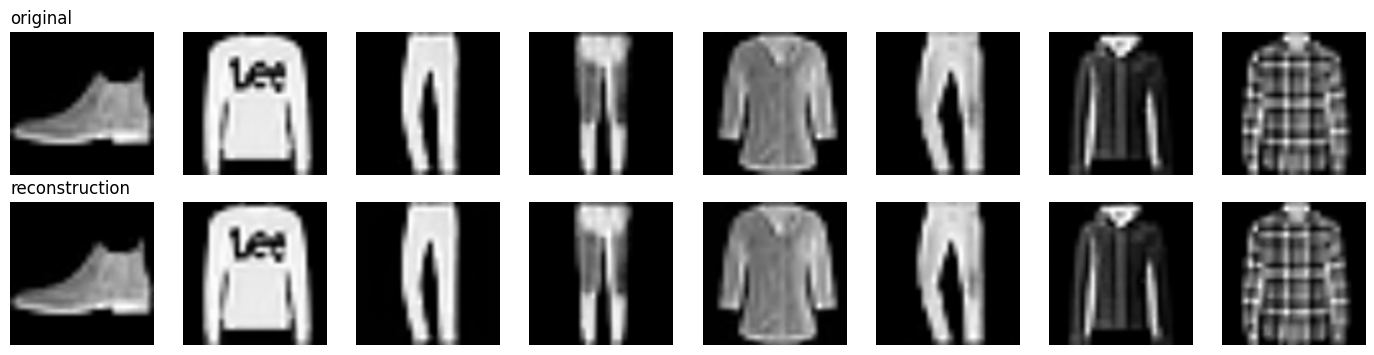

In [2]:
vae = AutoencoderKL.from_pretrained("stabilityai/sd-vae-ft-mse").to(device).eval()
for p in vae.parameters(): p.requires_grad_(False)

tfm = T.Compose([T.Resize(IMG), T.ToTensor(), T.Normalize([0.5], [0.5])])   # -> [-1, 1]
train_ds = torchvision.datasets.FashionMNIST("./data", train=True,  download=True, transform=tfm)
test_ds  = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=tfm)

@torch.no_grad()
def encode(x):                      # x: (B,1,H,W) in [-1,1]
    x3 = x.repeat(1, 3, 1, 1).to(device)
    with torch.autocast("cuda", dtype=torch.float16, enabled=(device == "cuda")):
        z = vae.encode(x3).latent_dist.mean
    return z.float() * SCALE        # scaled latents

@torch.no_grad()
def decode(z):                      # z: scaled latents
    with torch.autocast("cuda", dtype=torch.float16, enabled=(device == "cuda")):
        x = vae.decode(z.to(device) / SCALE).sample
    return x.float().clamp(-1, 1)   # (B,3,H,W)

@torch.no_grad()
def recon_check(xs, bs=16, keep=8):
    zs, m_pm1, m_01, xr_keep = [], [], [], None
    for i in range(0, len(xs), bs):
        xb = xs[i:i+bs]
        zb = encode(xb)
        xr = decode(zb)
        x3 = xb.repeat(1, 3, 1, 1).to(xr.device)
        m_pm1.append(F.mse_loss(xr, x3).item() * len(xb))
        m_01.append(F.mse_loss((xr + 1) / 2, (x3 + 1) / 2).item() * len(xb))
        zs.append(zb.cpu())
        if xr_keep is None: xr_keep = xr[:keep].cpu()     # first images, for plotting
        del xb, zb, xr, x3
        torch.cuda.empty_cache()
    n = len(xs)
    return torch.cat(zs), xr_keep, sum(m_pm1) / n, sum(m_01) / n

# Reconstruction check on 512 test images (chunked to avoid OOM)
xs = torch.stack([test_ds[i][0] for i in range(512)])
z, xr, mse_pm1, mse_01 = recon_check(xs, bs=16)
log(f"latent shape={tuple(z.shape)}  scaled latent std={z.std().item():.3f}")
log(f"VAE reconstruction MSE: {mse_pm1:.5f} ([-1,1] scale) | {mse_01:.5f} ([0,1] scale)")

fig, ax = plt.subplots(2, 8, figsize=(14, 3.6))
for i in range(8):
    ax[0, i].imshow(xs[i, 0], cmap="gray"); ax[0, i].axis("off")
    ax[1, i].imshow(xr[i].mean(0), cmap="gray"); ax[1, i].axis("off")
ax[0, 0].set_title("original", loc="left"); ax[1, 0].set_title("reconstruction", loc="left")
plt.tight_layout(); plt.show()

In [3]:
# Pre-encode the whole training set once (diffusion trains purely in latent space)
t0 = time.time()
loader = torch.utils.data.DataLoader(train_ds, batch_size=256, shuffle=False, num_workers=2)
lat_list, lab_list = [], []
for x, y in loader:
    lat_list.append(encode(x).cpu()); lab_list.append(y)
Z_train = torch.cat(lat_list).to(device)       # (60000,4,16,16)
Y_train = torch.cat(lab_list).to(device)
log(f"encoded {len(Z_train)} train images in {time.time()-t0:.0f}s; latent mean={Z_train.mean():.3f} std={Z_train.std():.3f}")

encoded 60000 train images in 65s; latent mean=-0.045 std=1.260


## 2. Forward diffusion in latent space
$q(z_t \mid z_0)=\mathcal N(\sqrt{\bar\alpha_t}\,z_0,\ (1-\bar\alpha_t)I)$, with $\beta_t$ linear from $10^{-4}$ to $0.02$ over $T=1000$ steps,
so $z_t=\sqrt{\bar\alpha_t}\,z_0+\sqrt{1-\bar\alpha_t}\,\epsilon$.

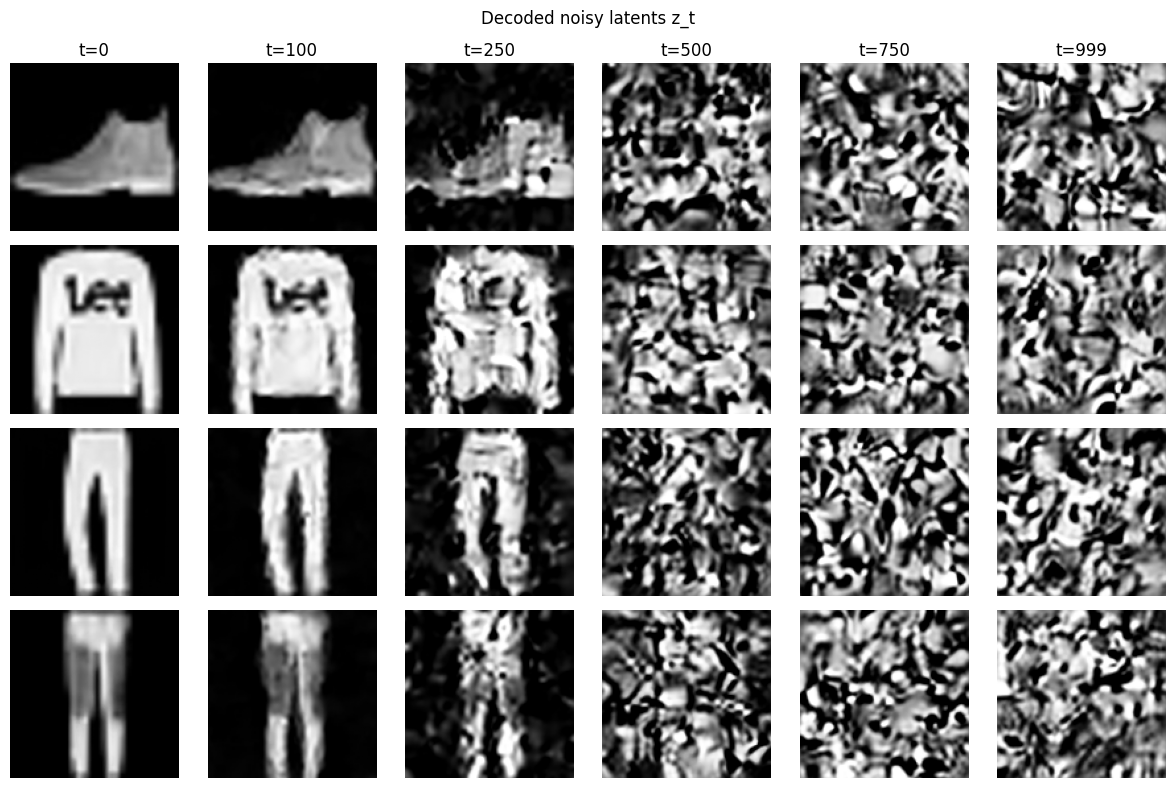

In [4]:
betas      = torch.linspace(BETA_1, BETA_T, T_STEPS, device=device)
alphas     = 1.0 - betas
alpha_bars = torch.cumprod(alphas, 0)

def q_sample(z0, t, noise=None):
    if noise is None: noise = torch.randn_like(z0)
    ab = alpha_bars[t].view(-1, 1, 1, 1)
    return ab.sqrt() * z0 + (1 - ab).sqrt() * noise, noise

# Visualize decoded noisy latents
show_t = [0, 100, 250, 500, 750, 999]
idx = [0, 1, 2, 3]
z0 = encode(torch.stack([test_ds[i][0] for i in idx]))
fig, ax = plt.subplots(len(idx), len(show_t), figsize=(2 * len(show_t), 2 * len(idx)))
g = torch.Generator(device=device).manual_seed(SEED)
for j, tt in enumerate(show_t):
    noise = torch.randn(z0.shape, device=device, generator=g)
    zt, _ = q_sample(z0, torch.full((len(idx),), tt, device=device), noise)
    imgs = decode(zt).mean(1).cpu()
    for i in range(len(idx)):
        ax[i, j].imshow(imgs[i], cmap="gray", vmin=-1, vmax=1); ax[i, j].axis("off")
        if i == 0: ax[i, j].set_title(f"t={tt}")
plt.suptitle("Decoded noisy latents z_t"); plt.tight_layout(); plt.show()

## 3. Conditional U-Net denoiser (base 64, mults (1,2,4), self-attention at 16x16 + bottleneck)

In [5]:
def sinusoidal_emb(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    a = t.float()[:, None] * freqs[None]
    return torch.cat([a.sin(), a.cos()], dim=-1)

class ResBlock(nn.Module):
    def __init__(self, cin, cout, tdim):
        super().__init__()
        self.n1 = nn.GroupNorm(32, cin);  self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
        self.t  = nn.Linear(tdim, cout)
        self.n2 = nn.GroupNorm(32, cout); self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
    def forward(self, x, emb):
        h = self.c1(F.silu(self.n1(x)))
        h = h + self.t(F.silu(emb))[:, :, None, None]
        h = self.c2(F.silu(self.n2(h)))
        return h + self.skip(x)

class SelfAttn(nn.Module):
    def __init__(self, c, heads=4):
        super().__init__()
        self.norm = nn.GroupNorm(32, c); self.qkv = nn.Conv2d(c, 3 * c, 1); self.proj = nn.Conv2d(c, c, 1); self.h = heads
    def forward(self, x):
        B, C, H, W = x.shape
        q, k, v = self.qkv(self.norm(x)).reshape(B, 3, self.h, C // self.h, H * W).transpose(-1, -2).unbind(1)
        o = F.scaled_dot_product_attention(q, k, v)                 # (B,h,HW,C/h)
        o = o.transpose(-1, -2).reshape(B, C, H, W)
        return x + self.proj(o)

class Down(nn.Module):
    def __init__(self, c): super().__init__(); self.conv = nn.Conv2d(c, c, 3, stride=2, padding=1)
    def forward(self, x): return self.conv(x)

class Up(nn.Module):
    def __init__(self, c): super().__init__(); self.conv = nn.Conv2d(c, c, 3, padding=1)
    def forward(self, x): return self.conv(F.interpolate(x, scale_factor=2, mode="nearest"))

def run(stage, h, emb):
    for l in stage: h = l(h, emb) if isinstance(l, ResBlock) else l(h)
    return h

class UNet(nn.Module):
    def __init__(self, in_ch=4, base=64, mults=(1, 2, 4), n_res=2, n_cls=10, attn_res=(16,), res=16):
        super().__init__()
        tdim = base * 4; self.base = base
        self.time_mlp  = nn.Sequential(nn.Linear(base, tdim), nn.SiLU(), nn.Linear(tdim, tdim))
        self.label_emb = nn.Embedding(n_cls + 1, tdim)               # index n_cls = null label
        self.conv_in   = nn.Conv2d(in_ch, base, 3, padding=1)
        self.down, chs, ch, r = nn.ModuleList(), [base], base, res
        for i, m in enumerate(mults):
            out = base * m
            for _ in range(n_res):
                blk = [ResBlock(ch, out, tdim)]; ch = out
                if r in attn_res: blk.append(SelfAttn(ch))
                self.down.append(nn.ModuleList(blk)); chs.append(ch)
            if i != len(mults) - 1:
                self.down.append(Down(ch)); chs.append(ch); r //= 2
        self.mid = nn.ModuleList([ResBlock(ch, ch, tdim), SelfAttn(ch), ResBlock(ch, ch, tdim)])   # bottleneck attention
        self.up = nn.ModuleList()
        for i, m in reversed(list(enumerate(mults))):
            out = base * m
            for _ in range(n_res + 1):
                blk = [ResBlock(ch + chs.pop(), out, tdim)]; ch = out
                if r in attn_res: blk.append(SelfAttn(ch))
                self.up.append(nn.ModuleList(blk))
            if i != 0: self.up.append(Up(ch)); r *= 2
        self.out = nn.Sequential(nn.GroupNorm(32, ch), nn.SiLU(), nn.Conv2d(ch, in_ch, 3, padding=1))

    def forward(self, x, t, y):
        emb = self.time_mlp(sinusoidal_emb(t, self.base)) + self.label_emb(y)   # combine time + label embeddings
        h = self.conv_in(x); hs = [h]
        for layer in self.down:
            h = layer(h) if isinstance(layer, Down) else run(layer, h, emb)
            hs.append(h)
        h = run(self.mid, h, emb)
        for layer in self.up:
            if isinstance(layer, Up): h = layer(h)
            else: h = run(layer, torch.cat([h, hs.pop()], 1), emb)
        return self.out(h)

model = UNet().to(device)
n_params = sum(p.numel() for p in model.parameters())
with torch.no_grad():
    o = model(torch.randn(2, 4, 16, 16, device=device), torch.tensor([5, 500], device=device), torch.tensor([3, NULL_LABEL], device=device))
assert o.shape == (2, 4, 16, 16)
log(f"U-Net params: {n_params/1e6:.2f}M | output shape {tuple(o.shape)}")

U-Net params: 14.49M | output shape (2, 4, 16, 16)


## 4. Training (50 epochs, LR 2e-5, epsilon-prediction, 10% label dropout)

epoch 01/50 loss=0.3594 elapsed=22s
epoch 06/50 loss=0.1213 elapsed=130s
epoch 11/50 loss=0.1104 elapsed=237s
epoch 16/50 loss=0.1042 elapsed=345s
epoch 21/50 loss=0.1019 elapsed=451s
epoch 26/50 loss=0.1001 elapsed=558s
epoch 31/50 loss=0.0963 elapsed=665s
epoch 36/50 loss=0.0976 elapsed=772s
epoch 41/50 loss=0.0956 elapsed=879s
epoch 46/50 loss=0.0944 elapsed=986s
epoch 50/50 loss=0.0932 elapsed=1072s


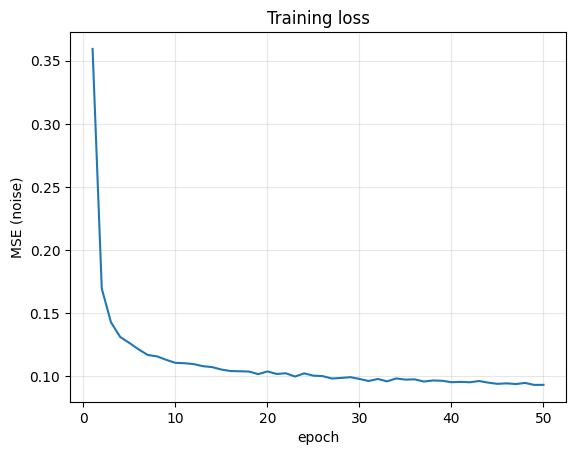

In [6]:
opt = torch.optim.AdamW(model.parameters(), lr=LR)
N = len(Z_train); steps_per_epoch = N // BS
loss_hist = []
t_start = time.time()
for ep in range(EPOCHS):
    model.train(); perm = torch.randperm(N, device=device); tot = 0.0
    for b in range(steps_per_epoch):
        ids = perm[b * BS:(b + 1) * BS]
        z0, y = Z_train[ids], Y_train[ids].clone()
        y[torch.rand(len(y), device=device) < P_UNCOND] = NULL_LABEL         # classifier-free dropout
        t = torch.randint(0, T_STEPS, (len(ids),), device=device)
        zt, eps = q_sample(z0, t)
        loss = F.mse_loss(model(zt, t, y), eps)
        opt.zero_grad(set_to_none=True); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        tot += loss.item()
    loss_hist.append(tot / steps_per_epoch)
    if ep % 5 == 0 or ep == EPOCHS - 1:
        log(f"epoch {ep+1:02d}/{EPOCHS} loss={loss_hist[-1]:.4f} elapsed={time.time()-t_start:.0f}s")
train_time = time.time() - t_start
torch.save(model.state_dict(), "ldm_unet.pt")
plt.plot(range(1, EPOCHS + 1), loss_hist); plt.xlabel("epoch"); plt.ylabel("MSE (noise)"); plt.title("Training loss"); plt.grid(alpha=.3); plt.show()

## 5. Sampling with classifier-free guidance
$\hat\epsilon=\epsilon_\theta(z_t,t,\varnothing)+w\,[\epsilon_\theta(z_t,t,c)-\epsilon_\theta(z_t,t,\varnothing)]$ with DDPM ancestral sampling in latent space, then VAE-decode.

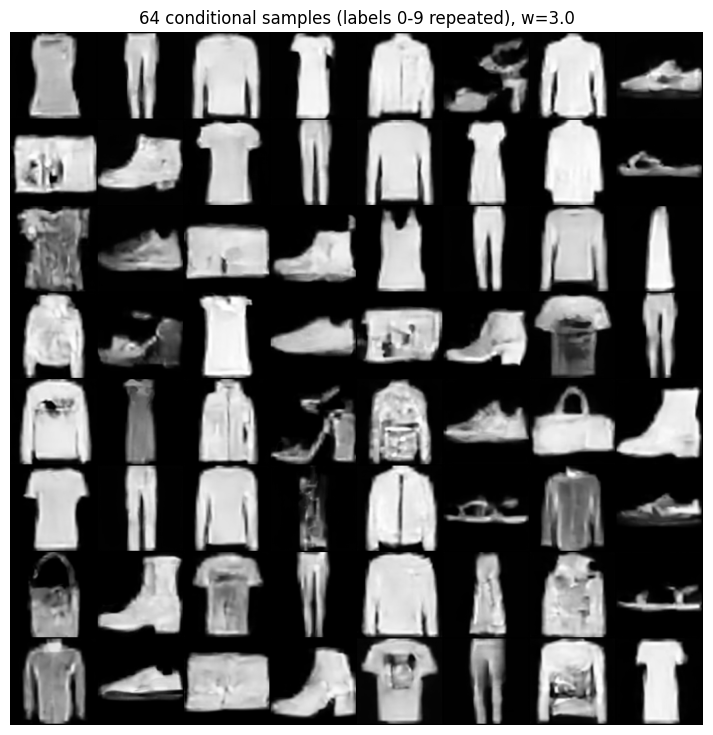

saved samples_64.png


In [7]:
@torch.no_grad()
def sample(labels, w=GUIDANCE_W, seed=SEED):
    model.eval()
    g = torch.Generator(device=device).manual_seed(seed)
    n = len(labels); y = torch.as_tensor(labels, device=device); yn = torch.full_like(y, NULL_LABEL)
    z = torch.randn(n, LAT_C, LAT, LAT, device=device, generator=g)
    for t in reversed(range(T_STEPS)):
        tt = torch.full((n,), t, device=device)
        e_c, e_u = model(torch.cat([z, z]), torch.cat([tt, tt]), torch.cat([y, yn])).chunk(2)
        e = e_u + w * (e_c - e_u)
        mean = (z - betas[t] / (1 - alpha_bars[t]).sqrt() * e) / alphas[t].sqrt()
        z = mean + betas[t].sqrt() * torch.randn(z.shape, device=device, generator=g) if t > 0 else mean
    return torch.cat([decode(c) for c in z.split(32)]).mean(1, keepdim=True).cpu()

labels64 = [i % 10 for i in range(64)]
imgs = sample(labels64)
grid = make_grid((imgs + 1) / 2, nrow=8, padding=2)
plt.figure(figsize=(9, 9)); plt.imshow(grid.permute(1, 2, 0).clamp(0, 1)); plt.axis("off")
plt.title(f"64 conditional samples (labels 0-9 repeated), w={GUIDANCE_W}"); plt.savefig("samples_64.png", dpi=150, bbox_inches="tight"); plt.show()
log("saved samples_64.png")

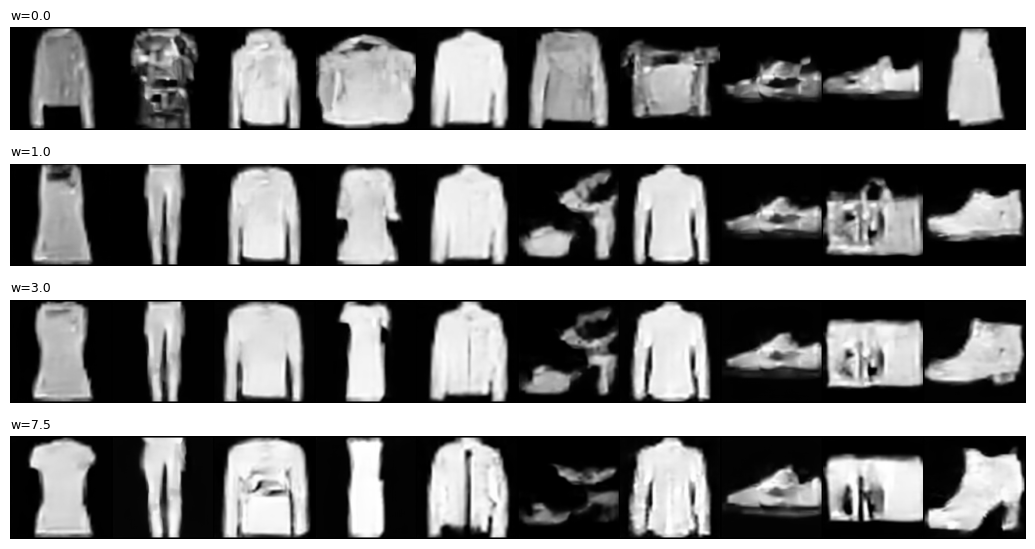

In [8]:
# Guidance-scale comparison: rows = w (0 = unconditional), columns = class 0-9
ws = [0.0, 1.0, 3.0, 7.5]
fig, ax = plt.subplots(len(ws), 1, figsize=(12, 1.4 * len(ws)))
for a, w in zip(ax, ws):
    row = sample(list(range(10)), w=w)
    a.imshow(make_grid((row + 1) / 2, nrow=10, padding=2).permute(1, 2, 0).clamp(0, 1)); a.axis("off"); a.set_title(f"w={w}", loc="left", fontsize=9)
plt.tight_layout(); plt.savefig("guidance_comparison.png", dpi=150); plt.show()

## Deliverable files

In [9]:
metrics = f"""# METRICS
- Seed: {SEED}
- VAE: stabilityai/sd-vae-ft-mse, scale={SCALE}, latent 4x16x16 (input resized to {IMG}x{IMG})
- VAE reconstruction MSE (512 test imgs): {mse_pm1:.5f} on [-1,1] scale, {mse_01:.5f} on [0,1] scale
- Diffusion: T={T_STEPS}, linear beta {BETA_1}..{BETA_T}
- U-Net params: {n_params/1e6:.2f}M (base 64, mults (1,2,4), attention at 16x16 + bottleneck)
- Training: {EPOCHS} epochs, LR {LR}, batch {BS}, label drop {P_UNCOND}; final loss {loss_hist[-1]:.4f}; time {train_time/60:.1f} min
- Sampling: DDPM {T_STEPS} steps, guidance scale w={GUIDANCE_W}
"""
open("METRICS.md", "w").write(metrics); open("RUN_LOG.txt", "w").write("\n".join(RUN_LOG))
print(metrics)

# METRICS
- Seed: 6638
- VAE: stabilityai/sd-vae-ft-mse, scale=0.18215, latent 4x16x16 (input resized to 128x128)
- VAE reconstruction MSE (512 test imgs): 0.00077 on [-1,1] scale, 0.00019 on [0,1] scale
- Diffusion: T=1000, linear beta 0.0001..0.02
- U-Net params: 14.49M (base 64, mults (1,2,4), attention at 16x16 + bottleneck)
- Training: 50 epochs, LR 2e-05, batch 128, label drop 0.1; final loss 0.0932; time 17.9 min
- Sampling: DDPM 1000 steps, guidance scale w=3.0

